In [55]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [56]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\trans_posada\aps884_22102026.xlsx')
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20619 entries, 0 to 20618
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  20619 non-null  str  
 1   Message  20619 non-null  str  
 2   Status   20619 non-null  str  
dtypes: str(3)
memory usage: 483.4 KB


In [57]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,3]=aux.iloc[i,2][0:8]

aux['Headers'].value_counts()

Headers
0x252521    18230
0x252513     1382
0x252501      545
0x252511      449
0x252514       13
Name: count, dtype: int64

In [58]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20619 entries, 0 to 20618
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  20619 non-null  str  
 1   Message  20619 non-null  str  
 2   Status   20619 non-null  str  
 3   Headers  20619 non-null  str  
dtypes: str(4)
memory usage: 644.5 KB


Odometer

In [59]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,2][96:104],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

#print(unit_aux['Odometer in meters'])

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 1395 entries, 0 to 20506
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Created             1395 non-null   str  
 1   Message             1395 non-null   str  
 2   Status              1395 non-null   str  
 3   Headers             1395 non-null   str  
 4   Odometer in meters  1395 non-null   int64
 5   Date                1395 non-null   str  
 6   Raw data            1395 non-null   str  
dtypes: int64(1), str(6)
memory usage: 87.2 KB
None


261001000031 -> 0 -> 6157747.0 -> 0x252513005906CA0869487060208492003C38402D00000059510000000000640000000000000000FFFFFFFFFFFF00D5005DF5B39726100100003100004E4221FE9DC211BE01C1005000A103892819FFFFFF0000260000FFFFFF
261001000036 -> 1 -> 6157755.0 -> 0x252513005906CB0869487060208492003C38402D0000005D510000000000640000000000000000FFFFFFFFFFFF00D5005DF5BB9726100100003600004C4222FE9DC259BE01C1006000D703892818FFFFFF0000260000FFFFFF
261001001112 -> 2 -> 6160816.0 -> 0x252513005906CC0869487060208492003C38402D00000056510000000000640000000000000000FFFFFFFFFFFF00D5005E01B0972610010011120000E84108079EC2101502C10110010803892830FFFFFF0000270000FFFFFF
261001001439 -> 3 -> 6161679.0 -> 0x252513005906CD0869487060208492003C38402D000000644F0000000000640000000000000000FFFFFFFFFFFF00D5005E050F992610010014399A99D941F70A9EC2471602C1022000D803892826FFFFFF0000270000FFFFFF
261001001445 -> 4 -> 6161718.0 -> 0x252513005906CE0869487060208492003C38402D00000064500000000000640000000000000000FFFFFFFFFFFF00D5005E053697

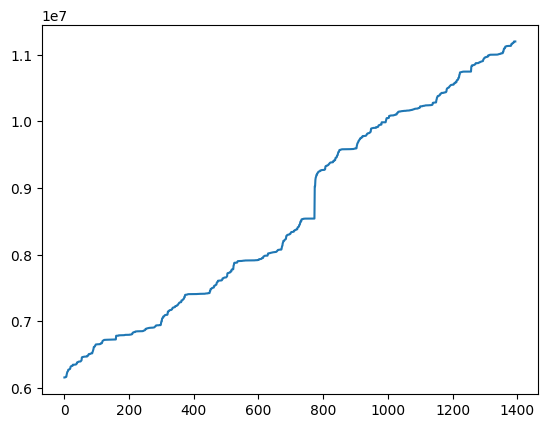

In [60]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,4]))
    x_axis.append(i)
    date.append(unit.iloc[i,5])
    raw_data_.append(unit.iloc[i,6])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

#print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [61]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux['Odometer in meters']=0.0
speed=[]
date=[]
raw=[]
unit_speed=pd.DataFrame()
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    try:
        lbs_ind=(bin(int(unit_aux.iloc[i,2][50:52],16) & 64))
        if lbs_ind=='0b1000000':
            speed.append(int(unit_aux.iloc[i,2][142:145]))  
            date.append(unit_aux.iloc[i,2][106:118])
            raw.append(unit_aux.iloc[i,2])
            print(lbs_ind)

    except:
        pass    

unit_speed['Speed']=speed
unit_speed['Date']=date
unit_speed['Raw data']=raw

unit=unit_speed.sort_values('Date',ascending=True)

print(unit.info())

0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000
0b1000000


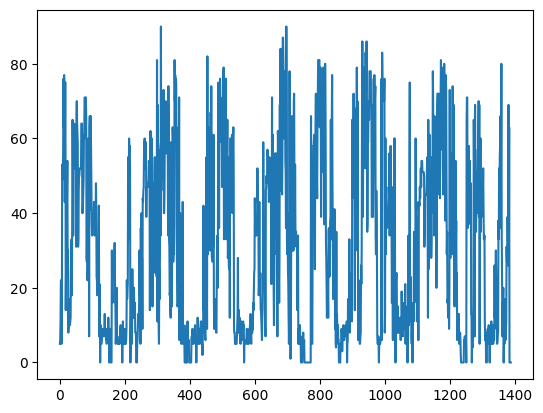

In [62]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,0]))
    x_axis.append(i)
    date.append(unit.iloc[i,1])
    raw_data_.append(unit.iloc[i,2])

plt.plot(x_axis,y_axis)

Historical events

In [63]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 0b10000000)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

print(satellite_connection_indicator)
unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)

unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,5]>0:
        num_events=num_events+1
        print(unit.iloc[i,5],'->', unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 128, 128, 128, 128, 128, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 0, 128, 128, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 128, 0, 128, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 128, 0, 0, 0, 0, 0, 0, 0, 0, 0

Satellites Number

In [64]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 128)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)

unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,4]<2:
        num_events=num_events+1
        print(unit.iloc[i,5],'->', unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 1395 entries, 0 to 20506
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         1395 non-null   str  
 1   Message                         1395 non-null   str  
 2   Status                          1395 non-null   str  
 3   Headers                         1395 non-null   str  
 4   Satellites                      1395 non-null   int64
 5   Satellite_connection_indicator  1395 non-null   int64
 6   Raw data                        1395 non-null   str  
 7   date                            1395 non-null   str  
dtypes: int64(2), str(6)
memory usage: 98.1 KB
0 -> 2026-10-05 13:21:03.274 -> 0 -> 0x252513005908240869487060208492003C38402D00000064000000000000640000000000000000FFFFFFFFFFFF00D5007107601026100513210382CC000A02104D11A0F100780000000003352830FFFFFF00001DFFFFFFFFFF
0 -> 2026-10-07 22:28:27.761 -> 0 -> 0x252513005909050

Coordinates

In [65]:
import struct

unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
latitude=[]
lat_aux=[]
longitude=[]
lon_aux=[]
speed=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    latitude.append(unit_aux.iloc[i,2][134:142])
    longitude.append(unit_aux.iloc[i,2][126:134])
    lon_aux.append(struct.unpack('<f', bytes.fromhex(unit_aux.iloc[i,2][126:134]))[0])
    lat_aux.append(struct.unpack('<f', bytes.fromhex(unit_aux.iloc[i,2][134:142]))[0])    
    speed.append(int(unit_aux.iloc[i,2][142:145],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Latitude']=latitude
unit_aux['Latitude_decoded']=lat_aux
unit_aux['Longitude']=longitude
unit_aux['Longitude_decoded']=lon_aux
unit_aux['Raw data']=raw
unit_aux['Date']=date
unit_aux['Speed']=speed

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

for i in range(0,unit.shape[0]):
    num_events=num_events+1
    print(unit.iloc[i,9],'->', unit.iloc[i,4], '->',unit.iloc[i,5],'->',unit.iloc[i,6],'->',unit.iloc[i,7],unit.iloc[i,8])

<class 'pandas.DataFrame'>
Index: 1395 entries, 0 to 20506
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Created            1395 non-null   str    
 1   Message            1395 non-null   str    
 2   Status             1395 non-null   str    
 3   Headers            1395 non-null   str    
 4   Latitude           1395 non-null   str    
 5   Latitude_decoded   1395 non-null   float64
 6   Longitude          1395 non-null   str    
 7   Longitude_decoded  1395 non-null   float64
 8   Raw data           1395 non-null   str    
 9   Date               1395 non-null   str    
 10  Speed              1395 non-null   int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 130.8 KB
None
261001000031 -> 11BE01C1 -> -8.108902931213379 -> 21FE9DC2 -> -78.99634552001953 0x252513005906CA0869487060208492003C38402D00000059510000000000640000000000000000FFFFFFFFFFFF00D5005DF5B39726100100003100004E4221FE9DC211BE

In/Outs

15      14                 13      12      11      10      09      08       07 06 05 04 03 02 01 00
Power   Ignition/Input0    Input1  Input2  Input3  Input4  Input5  Input0

15=0, Connected
15=1. Disconnected

In [66]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]
in_outs=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][64:68]
    aux_date.append(aux_cad[i][106:118])
    aux_raw_data.append(aux_cad[i])
    in_outs.append(bin (int (aux_cad[i][64:68],16) ))      

unit_=pd.DataFrame()
unit_['in and outs']=in_outs
unit_['date']=aux_date
unit_['raw data']=aux_raw_data

in_outs_df=unit_.sort_values('date',ascending=True)

in_outs_df.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\trans_posada\aps884_in_outs.csv')

Ignition

In [67]:
in_outs_df.info()

for i in range(0,in_outs_df.shape[0]):
    length=len(in_outs_df.iloc[i,0])
    if length>16:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0],in_outs_df.iloc[i,1])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0],in_outs_df.iloc[i,1])
    else:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0],in_outs_df.iloc[i,1])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0],in_outs_df.iloc[i,1])

<class 'pandas.DataFrame'>
Index: 1390 entries, 0 to 1376
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  1390 non-null   str  
 1   date         1390 non-null   str  
 2   raw data     1390 non-null   str  
dtypes: str(3)
memory usage: 43.4 KB
Ignition Off 0b0 261001000031
Ignition Off 0b0 261001000036
Ignition Off 0b0 261001001112
Ignition Off 0b0 261001001439
Ignition Off 0b0 261001001445
Ignition Off 0b0 261001003717
Ignition Off 0b0 261001005125
Ignition Off 0b0 261001021036
Ignition Off 0b0 261001024140
Ignition Off 0b0 261001030818
Ignition Off 0b0 261001031640
Ignition Off 0b0 261001032154
Ignition Off 0b0 261001033954
Ignition Off 0b0 261001034140
Ignition Off 0b0 261001034236
Ignition Off 0b0 261001034500
Ignition Off 0b0 261001034929
Ignition Off 0b0 261001034929
Ignition Off 0b0 261001035823
Ignition Off 0b0 261001042542
Ignition Off 0b0 261001043105
Ignition Off 0b0 261001045031
Ignition Off 

Door detection

In [68]:
x='0b0011000000000000' # for 16 bits, len=18

print(len(x),(x[4:6]))

y='0b011000000000000'   # for 15 bits, len=17
print(len(y), (y[3:5]))


18 11
17 11


In [69]:
in_outs=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sinthya\in_outs.csv',sep=',')
in_outs.info()
for i in range(0,in_outs.shape[0]):
    aux=(in_outs.iloc[i,1])
    if len(aux)==18:
        aux_2=(in_outs.iloc[i,1][4:6])
        if aux_2=='11':
            print(in_outs.iloc[i,1],len(aux),aux_2)
    if len(aux)==17:
        aux_2=(in_outs.iloc[i,1][3:5])
        if aux_2=='11':
            print(in_outs.iloc[i,1],len(aux),aux_2)

<class 'pandas.DataFrame'>
RangeIndex: 3378 entries, 0 to 3377
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Unnamed: 0   3378 non-null   int64
 1   in and outs  3378 non-null   str  
 2   date         3378 non-null   int64
 3   raw data     3378 non-null   str  
dtypes: int64(2), str(2)
memory usage: 105.7 KB


Panic detection

In [70]:
unit_.info()

<class 'pandas.DataFrame'>
RangeIndex: 1390 entries, 0 to 1389
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  1390 non-null   str  
 1   date         1390 non-null   str  
 2   raw data     1390 non-null   str  
dtypes: str(3)
memory usage: 32.7 KB


In [71]:
for i in range(0,unit_.shape[0]):
    if unit_.iloc[i,2][92:94]=='03':
        print(unit_.iloc[i,2],unit_.iloc[i,1])

0x252514005900190869487060208492003C38402D000000644E0000000000640000000000000000FFFFFFFFFFFF03D50071098600261006145316CDCC6642C90F9EC2768901C10000009F03922586FFFFFF0000230000FFFFFF 261006145316
0x2525140059001C0869487060208492003C38402D000000644F0000000700640000000000000000FFFFFFFFFFFF03D50071098600261006153704CDCC6642C90F9EC2768901C10000009F03932557FFFFFF0000240000FFFFFF 261006153704
0x2525140059001D0869487060208492003C38402D000000644F0000000700640000000000000000FFFFFFFFFFFF03D50071098600261006153706CDCC6642C90F9EC2768901C10000009F03932551FFFFFF0000240000FFFFFF 261006153706
0x2525140059001F0869487060208492003C38402D00000064520000000000640000000000000000FFFFFFFFFFFF03D500824F621126101016314500005E42E50F9EC2B58801C10000000003652820FFFFFF0000270000FFFFFF 261010163145


iButton

In [72]:
id_button_m=raw_data[raw_data['Headers'].str.contains('0x252523')]
device_id=[]
id_button_date=[]

id_button_m.info()

for i in range(0,id_button_m.shape[0]):
    device_id.append(id_button_m.iloc[i,2][84:100])
    id_button_date.append(id_button_m.iloc[i,2][32:44])
    print(id_button_m.iloc[i,2][84:100],id_button_m.iloc[i,2][32:44])

<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  0 non-null      str  
 1   Message  0 non-null      str  
 2   Status   0 non-null      str  
 3   Headers  0 non-null      str  
dtypes: str(4)
memory usage: 132.0 bytes
